#### This code is creating and analysing a synthetic dataset for simple feline acne DAG using dagitty. The DAG here is an extension of the one analysed in 3 - we add treatment compliance and recovery to the pet's journey.

In [1]:
# if not yet installed, install the required packages
# packgs <- c('ggplot2','dagitty','lme4','corrplot','semPlot','stringr','boot')
# install.packages(packgs)

In [2]:
rm(list=ls()) 
library(ggplot2)
library(dagitty)
library(lme4)
library(corrplot)
library(semPlot)
library(stringr)
library(boot)
# source the file with functions used in the project, includes DAG definitions:
# dag - dag definition
# functions: GenData, Factor.Analysis, reorder_mat, get_prevalence, createT2
source('0_supporting_functions.r')

Loading required package: Matrix

corrplot 0.92 loaded



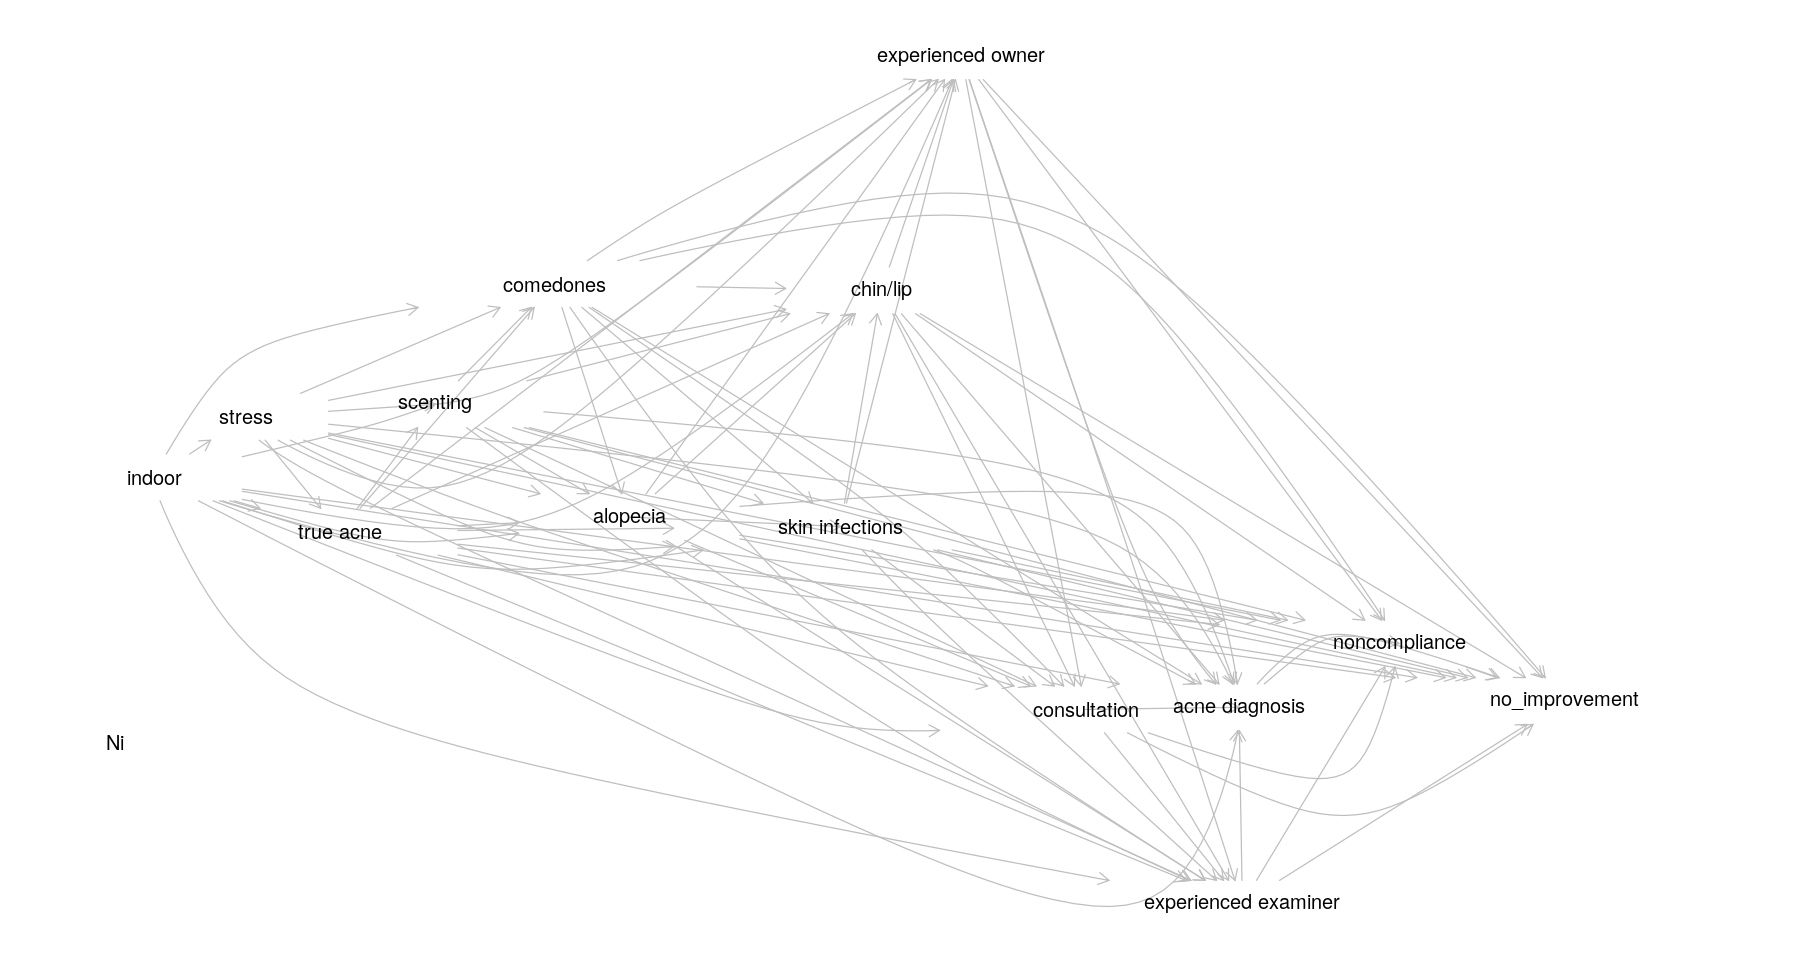

In [3]:
dag_moreVar <- dagitty('dag {
    bb="0,0,1,1"
    "acne diagnosis" [pos="0.786,0.661"]
    "chin/lip" [pos="0.576,0.262"]
    "experienced examiner" [pos="0.788,0.849"]
    "experienced owner" [pos="0.623,0.038"]
    "skin infections" [pos="0.552,0.488"]
    "true acne" [pos="0.258,0.493"]
    Ni [pos="0.126,0.695"]
    alopecia [pos="0.428,0.479"]
    comedones [pos="0.384,0.256"]
    noncompliance [pos="0.88,0.60"]
    consultation [pos="0.696,0.663"]
    no_improvement [pos="0.977,0.655"]
    indoor [pos="0.149,0.441"]
    scenting [pos="0.314,0.371"]
    stress [pos="0.203,0.383"]
    "acne diagnosis" -> noncompliance [pos="0.838,0.583",beta="-0.1"]
    "acne diagnosis" -> no_improvement [pos="0.830,0.569",beta="0"]
    "chin/lip" -> "acne diagnosis" [beta="0.4"]
    "chin/lip" -> "experienced examiner" [beta="0"]
    "chin/lip" -> "experienced owner" [beta="0.3"]
    "chin/lip" -> noncompliance [beta="-0.05"]
    "chin/lip" -> consultation [beta="0.001"]
    "chin/lip" -> no_improvement [beta="0.001"]
    "experienced examiner" -> "acne diagnosis" [beta="0.25"]
    "experienced examiner" -> noncompliance [beta="-0.15"]
    "experienced examiner" -> no_improvement [beta="-0.1"]
    "experienced owner" -> "acne diagnosis" [pos="0.732,0.573",beta="0.01"]
    "experienced owner" -> "experienced examiner" [pos="0.716,0.482",beta="0"]
    "experienced owner" -> noncompliance [beta="-0.1"]
    "experienced owner" -> consultation [beta="0.1"]
    "experienced owner" -> no_improvement [beta="-0.1"]
    "skin infections" -> "acne diagnosis" [pos="0.618,0.515",beta="0.1"]
    "skin infections" -> "chin/lip" [beta="0.1"]
    "skin infections" -> "experienced examiner" [pos="0.601,0.574",beta="0"]
    "skin infections" -> "experienced owner" [beta="0.5"]
    "skin infections" -> noncompliance [beta="-0.05"]
    "skin infections" -> consultation [beta="0.001"]
    "skin infections" -> no_improvement [beta="0.1"]
    "true acne" -> "acne diagnosis" [beta="0.2"]
    "true acne" -> "chin/lip" [beta="0.2"]
    "true acne" -> "experienced examiner" [beta="0"]
    "true acne" -> "experienced owner" [beta="0"]
    "true acne" -> "skin infections" [beta="0.01"]
    "true acne" -> alopecia [beta="0"]
    "true acne" -> comedones [beta="0.3"]
    "true acne" -> noncompliance [beta="0"]
    "true acne" -> consultation [beta="0"]
    "true acne" -> no_improvement [beta="0"]
    "true acne" -> scenting [beta="0.001"]
    alopecia -> "acne diagnosis" [pos="0.776,0.424",beta="0.01"]
    alopecia -> "chin/lip" [beta="0.01"]
    alopecia -> "experienced examiner" [beta="0"]
    alopecia -> "experienced owner" [beta="0.1"]
    alopecia -> "skin infections" [beta="0.1"]
    alopecia -> noncompliance [beta="-0.1"]
    alopecia -> consultation [beta="0"]
    alopecia -> no_improvement [beta="0"]
    comedones -> "acne diagnosis" [beta="0.3"]
    comedones -> "chin/lip" [beta="0.3"]
    comedones -> "experienced examiner" [pos="0.513,0.570",beta="0"]
    comedones -> "experienced owner" [pos="0.442,0.189",beta="0.3"]
    comedones -> "skin infections" [beta="0.3"]
    comedones -> alopecia [beta="0.1"]
    comedones -> noncompliance [pos="0.696,0.117",beta="-0.1"]
    comedones -> consultation [pos="0.592,0.484",beta="0.001"]
    comedones -> no_improvement [pos="0.686,0.074",beta="0"]
    noncompliance -> no_improvement [beta="0.4"]
    consultation -> "acne diagnosis" [beta="0.022"]
    consultation -> "experienced examiner" [beta="0"]
    consultation -> noncompliance [pos="0.862,0.764",beta="-0.1"]
    consultation -> no_improvement [pos="0.853,0.806",beta="-0.1"]
    indoor -> "acne diagnosis" [pos="0.776,0.981",beta="0.01"]
    indoor -> "chin/lip" [pos="0.373,0.532",beta="0.01"]
    indoor -> "experienced examiner" [pos="0.186,0.677",beta="0"]
    indoor -> "experienced owner" [pos="0.480,0.634",beta="0"]
    indoor -> "skin infections" [pos="0.339,0.547",beta="-0.1"]
    indoor -> "true acne" [beta="0"]
    indoor -> alopecia [pos="0.290,0.512",beta="0.01"]
    indoor -> comedones [pos="0.191,0.310",beta="0.1"]
    indoor -> noncompliance [beta="-0.1"]
    indoor -> consultation [pos="0.546,0.698",beta="0.2"]
    indoor -> no_improvement [beta="-0.1"]
    indoor -> scenting [pos="0.280,0.391",beta="0.05"]
    indoor -> stress [beta="0.2"]
    scenting -> "acne diagnosis" [pos="0.754,0.421",beta="0.01"]
    scenting -> "chin/lip" [beta="0.3"]
    scenting -> "experienced examiner" [pos="0.591,0.707",beta="0"]
    scenting -> "experienced owner" [pos="0.357,0.376",beta="0.01"]
    scenting -> "skin infections" [beta="0.1"]
    scenting -> alopecia [beta="0.1"]
    scenting -> comedones [beta="0.2"]
    scenting -> noncompliance [beta="0"]
    scenting -> consultation [beta="0"]
    scenting -> no_improvement [beta="0.001"]
    stress -> "acne diagnosis" [pos="0.753,0.464",beta="0.1"]
    stress -> "chin/lip" [beta="0.01"]
    stress -> "experienced examiner" [pos="0.218,0.427",beta="0"]
    stress -> "experienced owner" [pos="0.323,0.526",beta="0.01"]
    stress -> "skin infections" [pos="0.367,0.524",beta="0.01"]
    stress -> "true acne" [beta="0.1"]
    stress -> alopecia [beta="0.4"]
    stress -> comedones [beta="0.1"]
    stress -> noncompliance [beta="0.1"]
    stress -> consultation [pos="0.342,0.475",beta="0"]
    stress -> no_improvement [beta="0.1"]
    stress -> scenting [beta="0.5"]
    }


    '
)  

options(repr.plot.width=15, repr.plot.height=8)
plot(dag_moreVar)

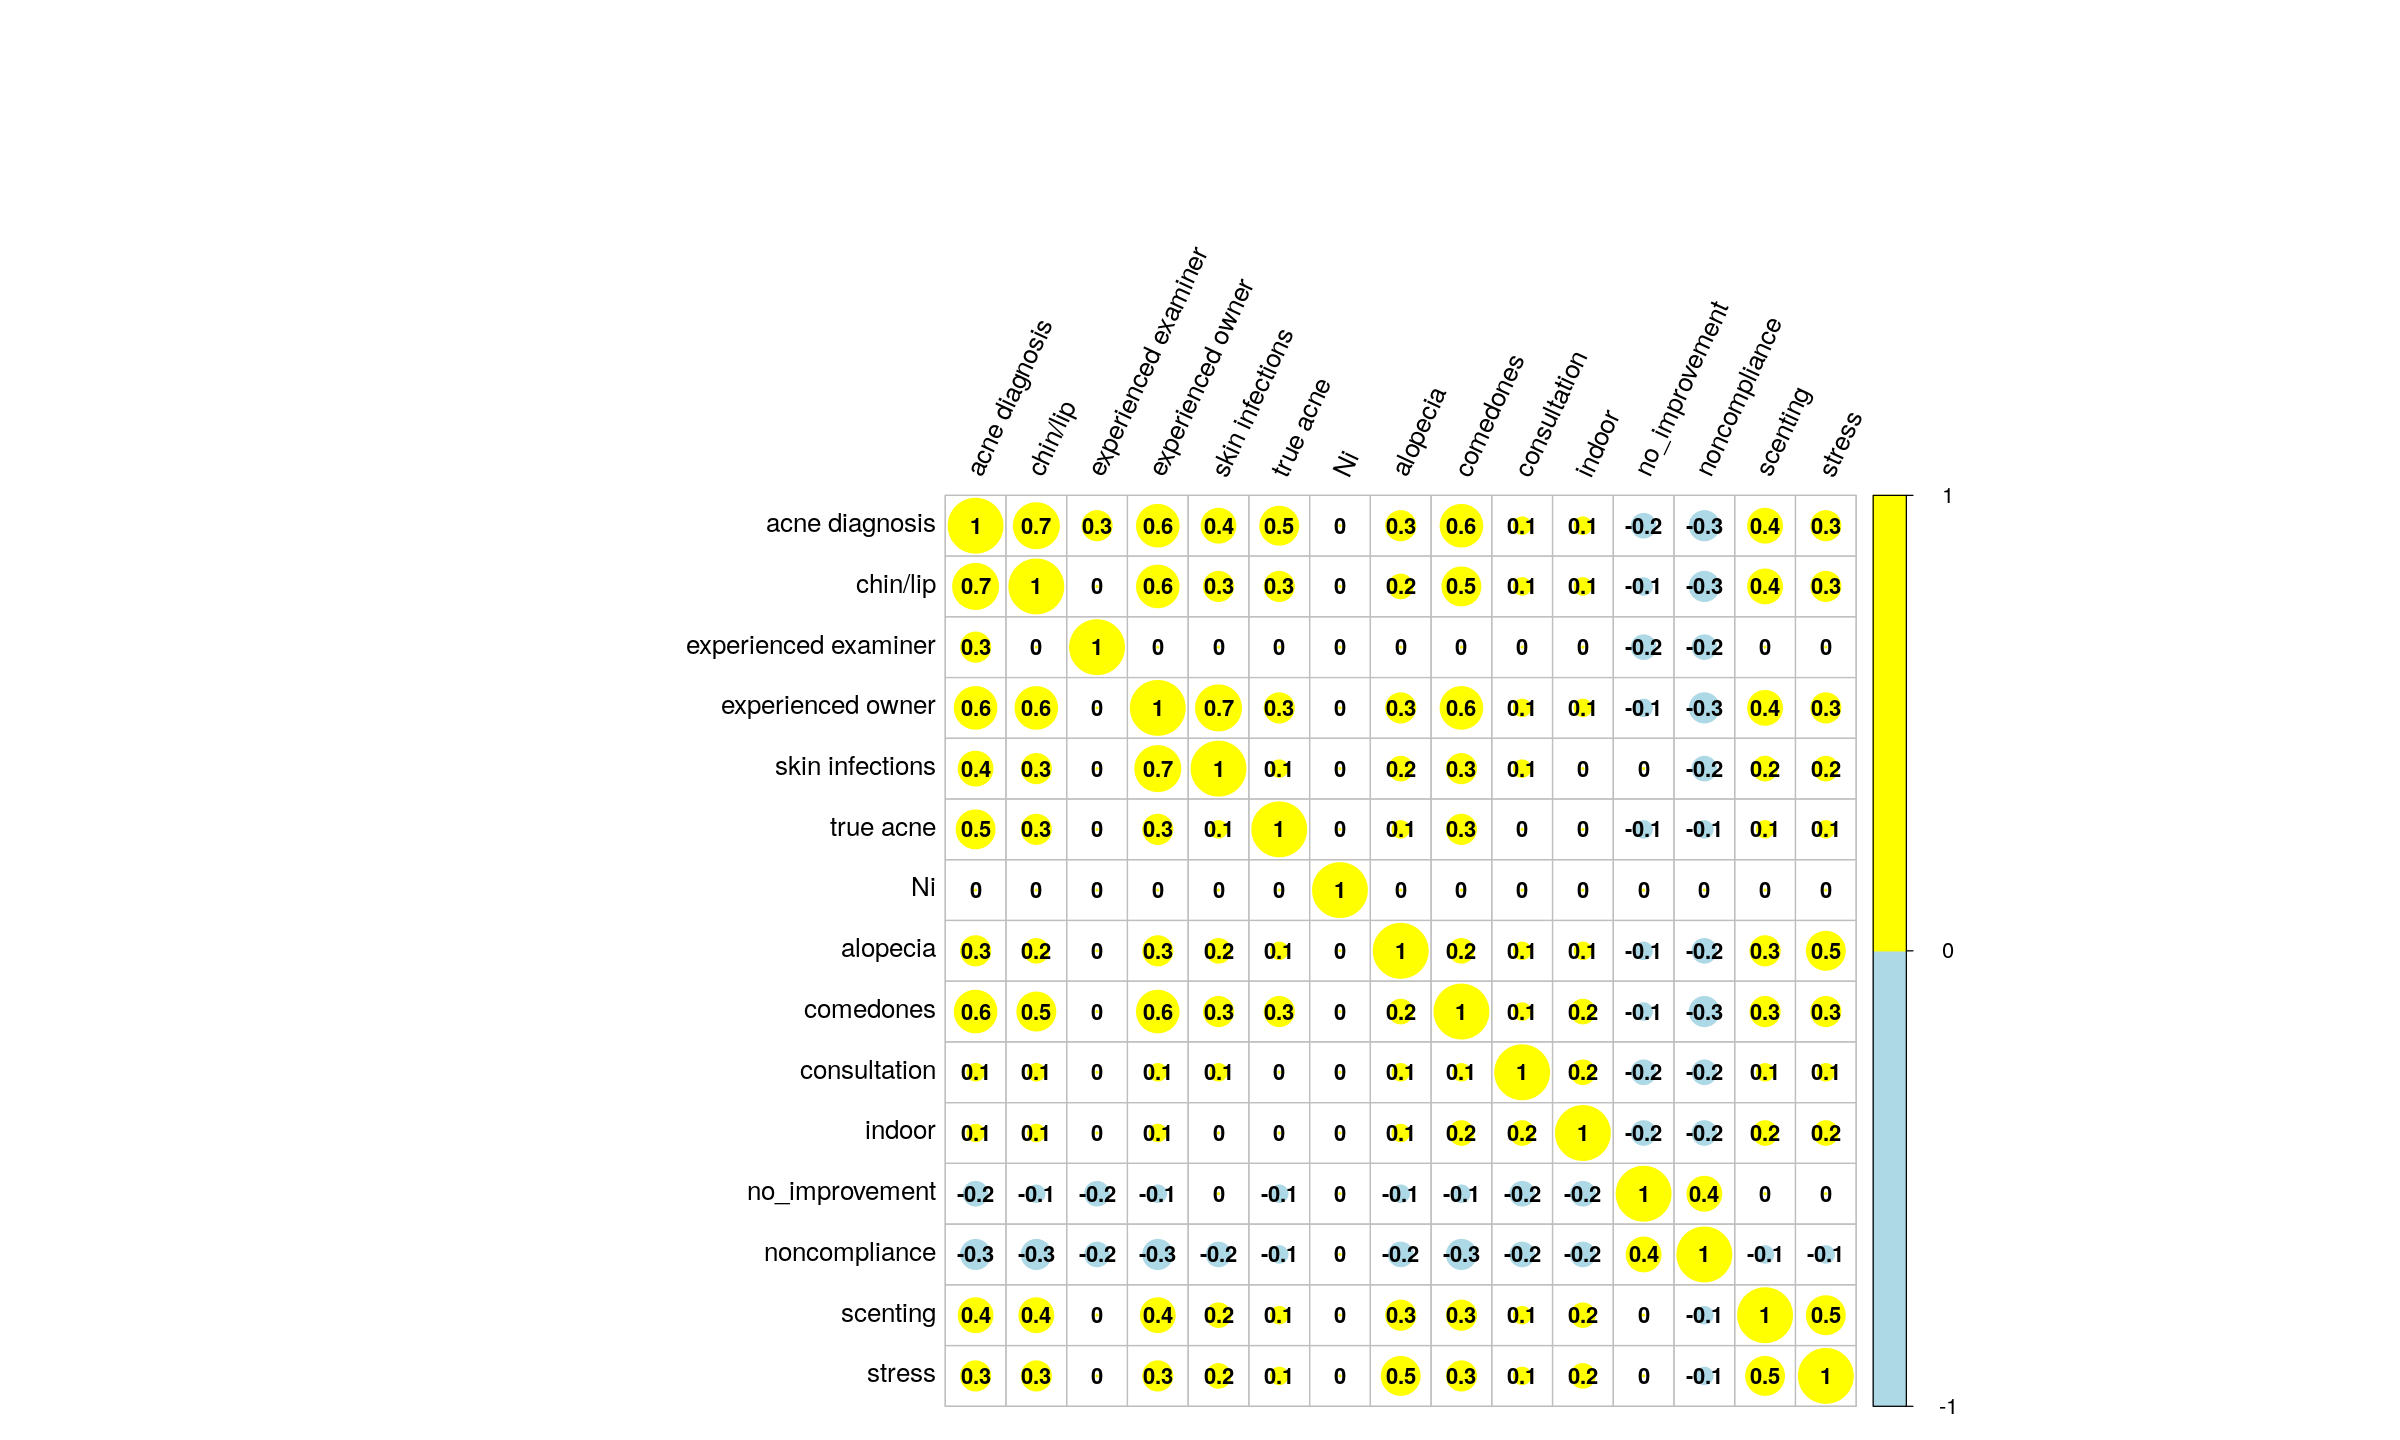

In [4]:
N <- 100000
set.seed(12)
mydataSEM <- simulateSEM(dag_moreVar, N=N, empirical=TRUE, b.default=0) 

options(repr.plot.width=20, repr.plot.height=12)
corrplot(round(cor(mydataSEM),1), addCoef.col = "black", tl.col="black", col=c("lightblue", "yellow"),
        tl.cex = 1.3, number.cex = 1.1, cl.cex = 1.1, tl.srt = 65)

##### <span style="color:blue">This section uses covariate Ni to generate clustering and examiner's experience; it is divided into six steps; N/C must be an integer but the code can be improved to skip that requirement</span>

In [5]:
C <- 50 # number of examiners
sdev_examiners <- 0.9 # standard deviation of the number of consultations per examiner
mean_examiners <- 1.2 # mean of the number of consultations per examiner
if (floor(N/C)!=ceiling(N/C)) print('Make sure N/C is an integer!')

In [6]:
# 1. order Ni ascending
Nhat <- mydataSEM$Ni[order(mydataSEM$Ni)]

In [7]:
# 2. rescale, with mean and standard deviation as defined above
Nhat <- Nhat*sdev_examiners + mean_examiners
# exponentiate to get the lognormal distribution 'back'
Nhat <- exp(Nhat)

In [8]:
# 3. divide the vector into C equal-size subgroups by creating 'subgroup' column
Nhat <- data.frame(Nhat)
Nhat$subgroup <- rep(1:C, each=N/C)

In [9]:
# 4. select 1 value in each subgroup and round it to the nearest integer to get C numbers of cluster size (Njhat)
select_rows <- runif(C)*N/C
# add a vector of 1, 2001, 4001,...
select_rows <- select_rows + seq(1,length.out = length(select_rows), by=N/C)
select_rows <- round(select_rows,0)
Njhat <- Nhat[select_rows,]
Njhat$Nhat <- round(Njhat$Nhat,0)
rm(select_rows)
rm(Nhat)

In [10]:
# 5. make Njhat sum to the population size by adding +/- 1 randomly -> Nj
while (N-sum(Njhat$Nhat)!=0)
{
    sample_rows <- sample(1:nrow(Njhat), size=min(abs(N-sum(Njhat$Nhat)),nrow(Njhat)))
    Njhat[sample_rows, 'Nhat'] <- Njhat[sample_rows, 'Nhat'] + 1*if(N-sum(Njhat$Nhat)<0){-1}else{1}
}
Nj <- Njhat$Nhat
rm(Njhat)

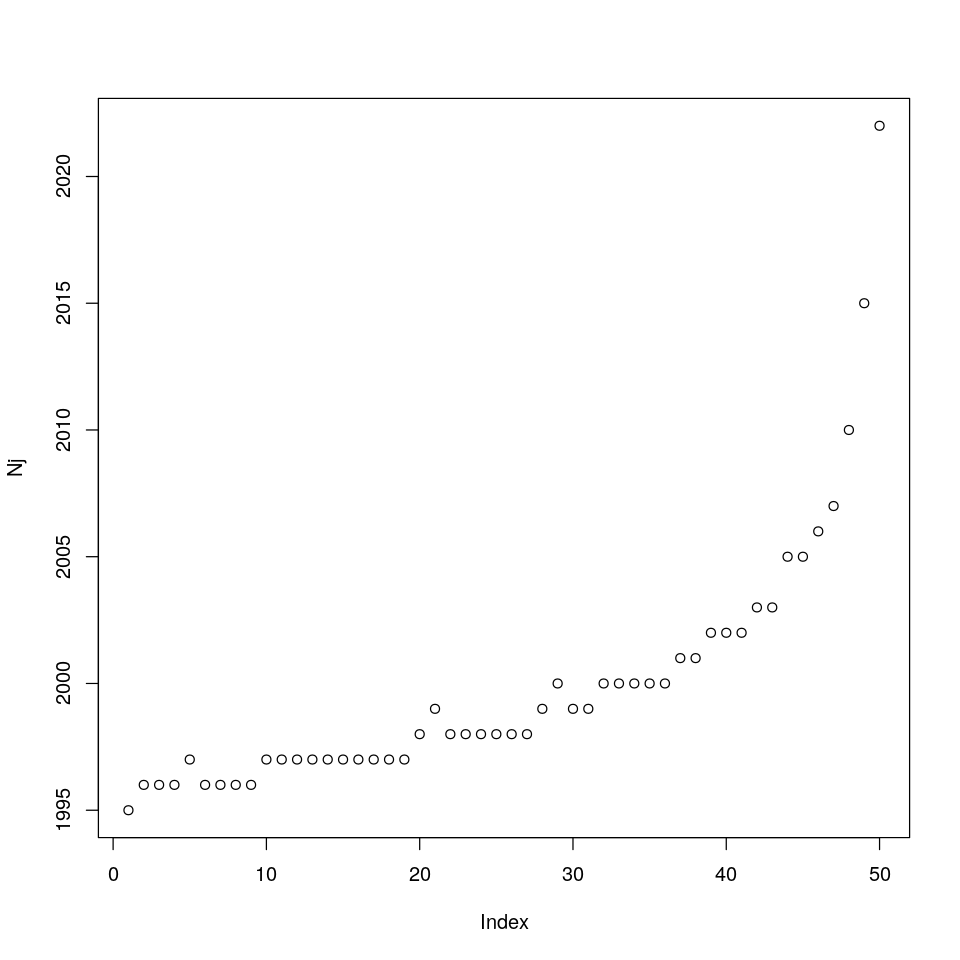

In [11]:
# 6. divide original Ni into C clusters of size Nj, j=1,2,...,C
mydataSEM <- mydataSEM[order(mydataSEM$Ni),]

Nj <- round(Nj/sum(Nj)*N,0)
# randomly +/-1 if sum(Nj)!=N
while (N-sum(Nj)!=0)
{
    sample_rows <- sample(1:length(Nj), size=min(abs(N-sum(Nj)),length(Nj)))
    Nj[sample_rows] <- Nj[sample_rows] + 1*if(N-sum(Nj)<0){-1}else{1}
}
options(repr.plot.width=8, repr.plot.height=8)
plot(Nj)

In [12]:
# 6. continued
mydataSEM$cluster <- rep(1:C,Nj)

In [13]:
Nj

[1] 1995 1996 1996 1996 1997 1996 1996 1996 1996 1997 1997 1997 1997 1997 1997
[16] 1997 1997 1997 1997 1998 1999 1998 1998 1998 1998 1998 1998 1999 2000 1999
[31] 1999 2000 2000 2000 2000 2000 2001 2001 2002 2002 2002 2003 2003 2005 2005
[46] 2006 2007 2010 2015 2022

In [14]:
rm(Nj)

In [15]:
# average by cluster
mydataSEM$'experienced examiner j' <- ave(mydataSEM$'experienced examiner', mydataSEM$cluster, FUN = mean, na.rm = TRUE)

In [16]:
head(mydataSEM)

,acne diagnosis,chin/lip,experienced examiner,experienced owner,skin infections,true acne,Ni,alopecia,comedones,consultation,indoor,no_improvement,noncompliance,scenting,stress,cluster,experienced examiner j
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
37091,-0.65521534,-0.26062157,0.7647264828,0.2840008,1.1825513,0.3458895,-4.646451,-1.4311858,-0.2800297,-1.0533069,-1.1104613,0.110980863,0.9340229,-1.5251339,-1.1642239,1,-0.02081526
13647,0.63968101,0.13757825,-1.1111526697,-0.4639847,-1.2146575,1.1958608,-4.301305,0.5048751,0.9388956,-0.4489846,0.5554904,-0.483546263,-0.5238845,1.1109426,1.4027279,1,-0.02081526
50475,0.77233363,-0.05102793,0.5488540036,-0.6008693,-0.8771133,0.5756150,-4.266818,-0.1275561,0.4714850,-1.6929301,-0.2117585,0.006103879,0.5046311,0.5967537,0.6600703,1,-0.02081526
90724,-1.28769314,-0.95058581,1.3185603752,-0.6094563,-0.4479260,0.5578068,-4.191647,0.2671415,-0.9373214,0.7438065,0.5205224,-0.445854259,0.4100267,-1.1479365,-0.1473099,1,-0.02081526
33414,1.50466107,0.54237784,0.5981580508,0.5321609,0.1947203,0.4038379,-4.015341,-0.0687440,0.8360422,0.8756644,1.0725407,-0.653021052,-0.8606547,0.4693724,0.1830198,1,-0.02081526
35234,0.03830992,-0.38661084,0.0001409725,-0.3468209,-0.2640164,-0.2179479,-3.911688,1.3983118,0.9834316,-0.6917711,-0.2005941,-0.512295790,0.2468204,0.2522022,0.1746829,1,-0.02081526


#### dichotomise the covariates

In [17]:
mydataSEM <- mydataSEM[order(mydataSEM$'acne diagnosis',decreasing = TRUE),]
percent_of1s <- 0.28
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'acne diagnosis' <- 0
mydataSEM[1:num_rows_of1s,'acne diagnosis'] <- 1

In [18]:
mydataSEM <- mydataSEM[order(mydataSEM$'chin/lip',decreasing = TRUE),]
percent_of1s <- 3
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'chin/lip' <- 0
mydataSEM[1:num_rows_of1s,'chin/lip'] <- 1

In [19]:
mydataSEM <- mydataSEM[order(mydataSEM$'experienced owner',decreasing = TRUE),]
percent_of1s <- 34
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'experienced owner' <- 0
mydataSEM[1:num_rows_of1s,'experienced owner'] <- 1

In [20]:
mydataSEM <- mydataSEM[order(mydataSEM$'skin infections',decreasing = TRUE),]
percent_of1s <- 2
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'skin infections' <- 0
mydataSEM[1:num_rows_of1s,'skin infections'] <- 1

In [21]:
mydataSEM <- mydataSEM[order(mydataSEM$'true acne',decreasing = TRUE),]
percent_of1s <- 5
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'true acne' <- 0
mydataSEM[1:num_rows_of1s,'true acne'] <- 1

In [22]:
mydataSEM <- mydataSEM[order(mydataSEM$'alopecia',decreasing = TRUE),]
percent_of1s <- 1
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'alopecia' <- 0
mydataSEM[1:num_rows_of1s,'alopecia'] <- 1

In [23]:
mydataSEM <- mydataSEM[order(mydataSEM$'comedones',decreasing = TRUE),]
percent_of1s <- 3
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'comedones' <- 0
mydataSEM[1:num_rows_of1s,'comedones'] <- 1

In [24]:
mydataSEM <- mydataSEM[order(mydataSEM$'consultation',decreasing = TRUE),]
percent_of1s <- 21.7
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'consultation' <- 0
mydataSEM[1:num_rows_of1s,'consultation'] <- 1

In [25]:
mydataSEM <- mydataSEM[order(mydataSEM$'indoor',decreasing = TRUE),]
percent_of1s <- 26.1
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'indoor' <- 0
mydataSEM[1:num_rows_of1s,'indoor'] <- 1

In [26]:
mydataSEM <- mydataSEM[order(mydataSEM$'scenting',decreasing = TRUE),]
percent_of1s <- 25
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'scenting' <- 0
mydataSEM[1:num_rows_of1s,'scenting'] <- 1

In [27]:
mydataSEM <- mydataSEM[order(mydataSEM$'stress',decreasing = TRUE),]
percent_of1s <- 25
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'stress' <- 0
mydataSEM[1:num_rows_of1s,'stress'] <- 1

In [28]:
mydataSEM <- mydataSEM[order(mydataSEM$'noncompliance',decreasing = TRUE),]
percent_of1s <- 36
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'noncompliance' <- 0
mydataSEM[1:num_rows_of1s,'noncompliance'] <- 1

In [29]:
mydataSEM <- mydataSEM[order(mydataSEM$'no_improvement',decreasing = TRUE),]
percent_of1s <- 35
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'no_improvement' <- 0
mydataSEM[1:num_rows_of1s,'no_improvement'] <- 1

In [30]:
# solvers don't like names with spaces
names2change <- colnames(mydataSEM)
new_names <- str_replace(names2change, " ", "_")
new_names <- str_replace(new_names, " ", "_")
new_names <- str_replace(new_names, " ", "_")
new_names <- str_replace(new_names, "/", "_")
colnames(mydataSEM) <- new_names

In [31]:
# pets that have had a consultation
mydata_consult1 <- mydataSEM[mydataSEM$consultation==1,]

### 'table 2' calculated for compliance and improvement
we use consulted pets only, and account for the examiner by clustering, acne diagnosis is used as a covariate

#### noncompliance

In [32]:
m2  <-   glmer(noncompliance ~ 1 +                   + experienced_owner  + chin_lip     + 
                                  skin_infections + alopecia           + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m3  <-   glmer(noncompliance ~ 1 +                                         + chin_lip     + 
                                  skin_infections + alopecia           + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m4  <-   glmer(noncompliance ~ 1 +  skin_infections + alopecia           + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m5  <-   glmer(noncompliance ~ 1 +                   + alopecia           + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m6  <-   glmer(noncompliance ~ 1 +                                         + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m7  <-   glmer(noncompliance ~ 1 +                                                         + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m8  <-   glmer(noncompliance ~ 1 +  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m9  <-   glmer(noncompliance ~ 1 +                   + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')



In [33]:
v <- list('experienced_owner',m2,
          'chin_lip',m3,
          'skin_infections',m4,
          'alopecia',m5,
          'comedones',m6,
          'scenting',m7,
          'stress',m8,
          'indoor',m9)
T2 <- createT2(v)

In [34]:
# since it is logistic, exponentiate and create CI
T2$'exp_reg_coeff' <- exp(T2$'reg_coeff')
T2$'CI_left' <- exp(T2$'reg_coeff'-1.96*T2$'std_error')
T2$'CI_right' <- exp(T2$'reg_coeff'+1.96*T2$'std_error')
T2

,covariate,reg_coeff,std_error,adjusted_for,exp_reg_coeff,CI_left,CI_right
,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,experienced_owner,-0.7916329,0.03596385,"chin_lip, skin_infections, alopecia, comedones, scenting, stress, indoor",0.4531043,0.4222651,0.4861958
2,chin_lip,-0.8426399,0.11304005,"skin_infections, alopecia, comedones, scenting, stress, indoor",0.4305724,0.3450043,0.5373630
3,skin_infections,-0.9203980,0.13266786,"alopecia, comedones, scenting, stress, indoor",0.3983605,0.3071475,0.5166606
4,alopecia,-0.7788790,0.17882451,"comedones, scenting, stress, indoor",0.4589202,0.3232352,0.6515618
5,comedones,-0.9397102,0.10555104,"scenting, stress, indoor",0.3907411,0.3177183,0.4805471
6,scenting,-0.3216410,0.03707623,"stress, indoor",0.7249584,0.6741448,0.7796021
7,stress,-0.1863032,0.03472521,indoor,0.8300219,0.7754090,0.8884812
8,indoor,-0.3760955,0.03236995,,0.6865368,0.6443324,0.7315056


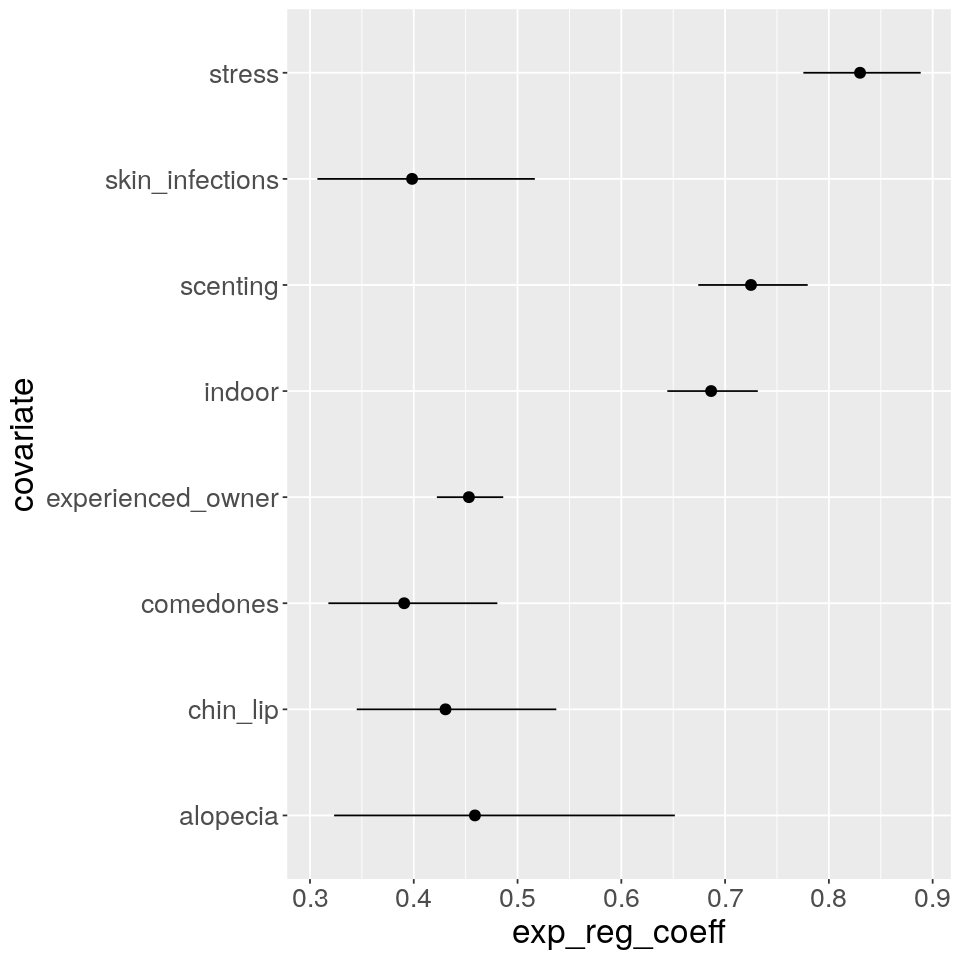

In [35]:
ggplot(T2, aes(x=covariate,y=exp_reg_coeff,ymin=CI_left,ymax=CI_right)) +
    geom_pointrange(position = position_dodge2(width = 0.2)) + 
    theme(text = element_text(size = 20)) +
    coord_flip()

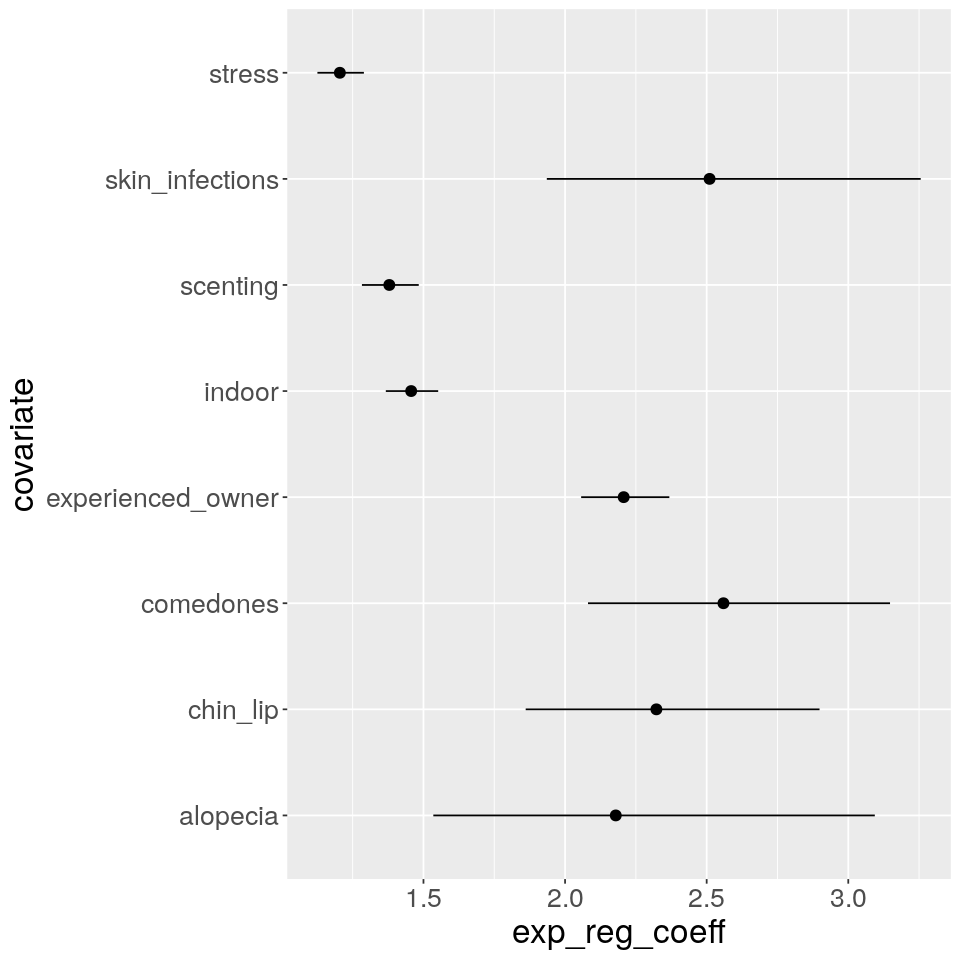

In [36]:
# compliance
ggplot(T2, aes(x=covariate,y=1/exp_reg_coeff,ymin=1/CI_left,ymax=1/CI_right)) +
    geom_pointrange(position = position_dodge2(width = 0.2)) + 
    theme(text = element_text(size = 20)) +
    coord_flip() +
    labs(y= "exp_reg_coeff")

#### no_improvement

In [37]:
m0  <-   glmer(no_improvement ~ 1 +  noncompliance  +
                                      acne_diagnosis  + experienced_owner  + chin_lip     + 
                                  skin_infections + alopecia           + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m2  <-   glmer(no_improvement ~ 1 +                   + experienced_owner  + chin_lip     + 
                                  skin_infections + alopecia           + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m3  <-   glmer(no_improvement ~ 1 +                                         + chin_lip     + 
                                  skin_infections + alopecia           + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m4  <-   glmer(no_improvement ~ 1 +  skin_infections + alopecia           + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m5  <-   glmer(no_improvement ~ 1 +                   + alopecia           + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m6  <-   glmer(no_improvement ~ 1 +                                         + comedones    + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m7  <-   glmer(no_improvement ~ 1 +                                                         + scenting  + 
                                  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m8  <-   glmer(no_improvement ~ 1 +  stress          + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

m9  <-   glmer(no_improvement ~ 1 +                   + indoor             + (1|cluster),
             data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')



In [38]:
v <- list('noncompliance',m0,         
          'experienced_owner',m2,
          'chin_lip',m3,
          'skin_infections',m4,
          'alopecia',m5,
          'comedones',m6,
          'scenting',m7,
          'stress',m8,
          'indoor',m9)
T2 <- createT2(v)

In [39]:
# since it is logistic, exponentiate and create CI
T2$'exp_reg_coeff' <- exp(T2$'reg_coeff')
T2$'CI_left' <- exp(T2$'reg_coeff'-1.96*T2$'std_error')
T2$'CI_right' <- exp(T2$'reg_coeff'+1.96*T2$'std_error')
T2

,covariate,reg_coeff,std_error,adjusted_for,exp_reg_coeff,CI_left,CI_right
,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,noncompliance,1.16838844,0.03369743,"acne_diagnosis, experienced_owner, chin_lip, skin_infections, alopecia, comedones, scenting, stress, indoor",3.2168044,3.0112084,3.4364378
2,experienced_owner,-0.37756609,0.03520984,"chin_lip, skin_infections, alopecia, comedones, scenting, stress, indoor",0.6855279,0.6398142,0.7345077
3,chin_lip,-0.24012434,0.09090916,"skin_infections, alopecia, comedones, scenting, stress, indoor",0.7865301,0.6581606,0.9399370
4,skin_infections,-0.10270338,0.10338229,"alopecia, comedones, scenting, stress, indoor",0.9023946,0.7368782,1.1050890
5,alopecia,-0.36098490,0.15074968,"comedones, scenting, stress, indoor",0.6969895,0.5186872,0.9365845
6,comedones,-0.47772772,0.09117957,"scenting, stress, indoor",0.6201910,0.5186948,0.7415477
7,scenting,-0.02831476,0.03662528,"stress, indoor",0.9720824,0.9047467,1.0444295
8,stress,0.15502371,0.03444708,indoor,1.1676857,1.0914504,1.2492458
9,indoor,-0.43682339,0.03344592,,0.6460855,0.6050904,0.6898581


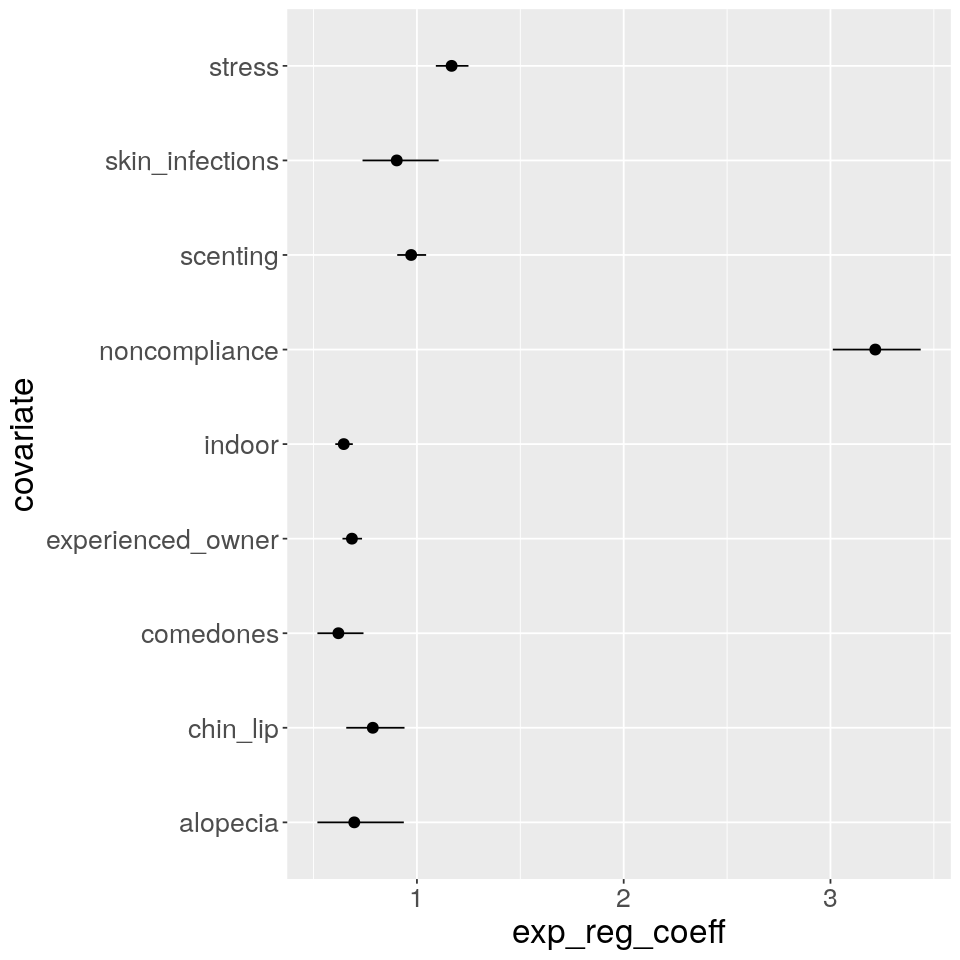

In [40]:
ggplot(T2, aes(x=covariate,y=exp_reg_coeff,ymin=CI_left,ymax=CI_right)) +
    geom_pointrange(position = position_dodge2(width = 0.2)) + 
    theme(text = element_text(size = 20)) +
    coord_flip()

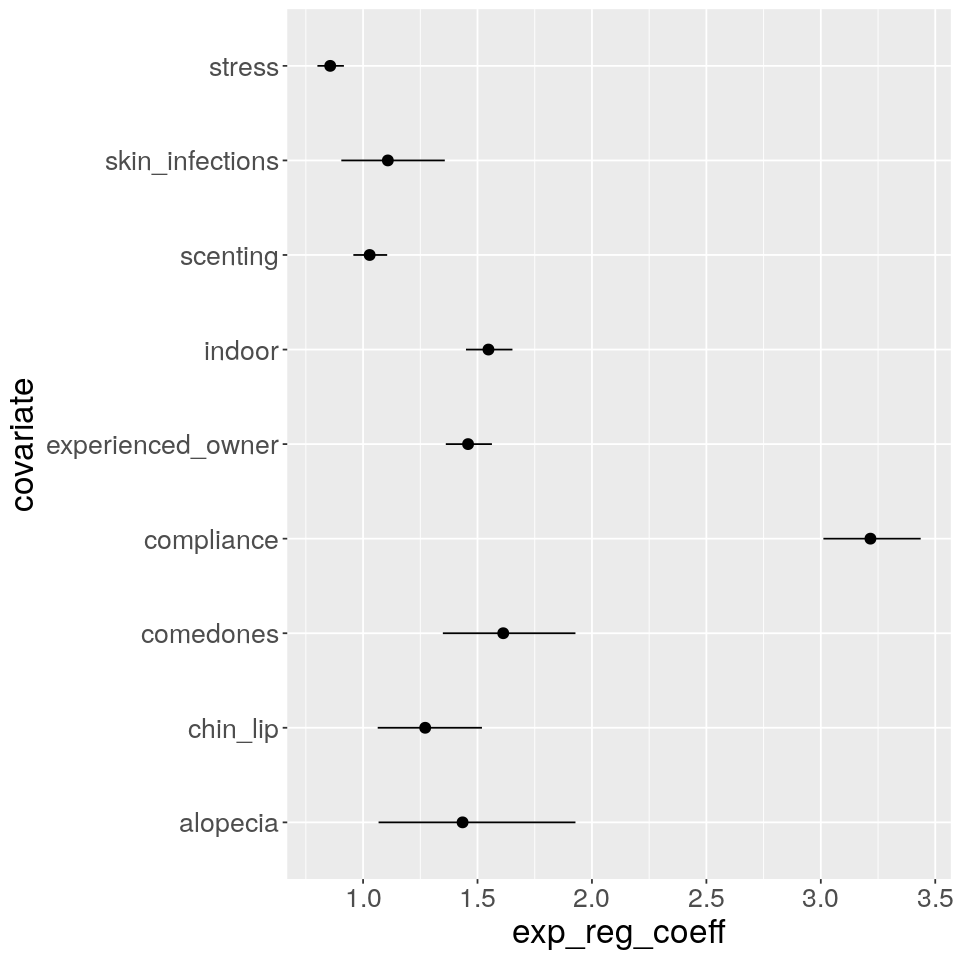

In [41]:
# improvement
T2[T2$covariate=='noncompliance','exp_reg_coeff'] <- 1/T2[T2$covariate=='noncompliance','exp_reg_coeff']
T2[T2$covariate=='noncompliance','CI_left'] <- 1/T2[T2$covariate=='noncompliance','CI_left']
T2[T2$covariate=='noncompliance','CI_right'] <- 1/T2[T2$covariate=='noncompliance','CI_right']
T2[T2$covariate=='noncompliance','covariate'] <- 'compliance'
ggplot(T2, aes(x=covariate,y=1/exp_reg_coeff,ymin=1/CI_left,ymax=1/CI_right)) +
    geom_pointrange(position = position_dodge2(width = 0.2)) + 
    theme(text = element_text(size = 20)) +
    coord_flip() +
    labs(y= "exp_reg_coeff")

#### prevalence

In [42]:
# datasets with not consulted and consulted pets
mydata_consult0 <- mydataSEM[mydataSEM$consultation==0,]
mydata_consult1 <- mydataSEM[mydataSEM$consultation==1,]

In [43]:
num_consult0 <- nrow(mydata_consult0)
num_consult1 <- nrow(mydata_consult1)
print(num_consult0)
print(num_consult1)

[1] 78300
[1] 21700


In [44]:
get_prevalence <- function(mydata)
{
    mydata_consult0 <- mydata[mydata$consultation==0,]
    mydata_consult1 <- mydata[mydata$consultation==1,]

    num_consult0 <- nrow(mydata_consult0)
    num_consult1 <- nrow(mydata_consult1)
    prevalence <- data.frame(covariate = character(0),
                                     dataset = character(0),
                                     percentage1 = numeric(0))
    # consulted
    prevalence <- rbind(prevalence,
                               c('experienced_owner','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'experienced_owner'==1,])/num_consult1*100),
                               c('chin_lip','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'chin_lip'==1,])/num_consult1*100),
                               c('skin_infections','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'skin_infections'==1,])/num_consult1*100),
                               c('alopecia','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'alopecia'==1,])/num_consult1*100),
                               c('comedones','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'comedones'==1,])/num_consult1*100),
                               c('scenting','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'scenting'==1,])/num_consult1*100),
                               c('true_acne','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'true_acne'==1,])/num_consult1*100),
                               c('stress','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'stress'==1,])/num_consult1*100),
                               c('indoor','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'indoor'==1,])/num_consult1*100),
                               c('acne_diagnosis','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'acne_diagnosis'==1,])/num_consult1*100),
                               c('noncompliance','consulted',
                                 nrow(mydata_consult1[mydata_consult1$'noncompliance'==1,])/num_consult1*100),
                               c('no_improvement','consulted',
                                         nrow(mydata_consult1[mydata_consult1$'no_improvement'==1,])/num_consult1*100))
    # non-consulted
    prevalence <- rbind(prevalence,
                               c('experienced_owner','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'experienced_owner'==1,])/num_consult0*100),
                               c('chin_lip','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'chin_lip'==1,])/num_consult0*100),
                               c('skin_infections','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'skin_infections'==1,])/num_consult0*100),
                               c('alopecia','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'alopecia'==1,])/num_consult0*100),
                               c('comedones','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'comedones'==1,])/num_consult0*100),
                               c('scenting','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'scenting'==1,])/num_consult0*100),
                               c('true_acne','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'true_acne'==1,])/num_consult0*100),
                               c('stress','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'stress'==1,])/num_consult0*100),
                               c('indoor','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'indoor'==1,])/num_consult0*100),
                               c('noncompliance','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'noncompliance'==1,])/num_consult0*100), 
                               c('no_improvement','non-consulted',
                                 nrow(mydata_consult0[mydata_consult0$'no_improvement'==1,])/num_consult0*100))
    colnames(prevalence) <- c('covariate','dataset','percentage1')
    prevalence$percentage1 <- round(as.numeric(prevalence$percentage1),2)
    return(prevalence)    
}

In [45]:
prevalence_dagitty <- get_prevalence(mydataSEM)

In [46]:
head(prevalence_dagitty)

,covariate,dataset,percentage1
,<chr>,<chr>,<dbl>
1,experienced_owner,consulted,39.49
2,chin_lip,consulted,3.69
3,skin_infections,consulted,2.49
4,alopecia,consulted,1.33
5,comedones,consulted,3.97
6,scenting,consulted,27.94


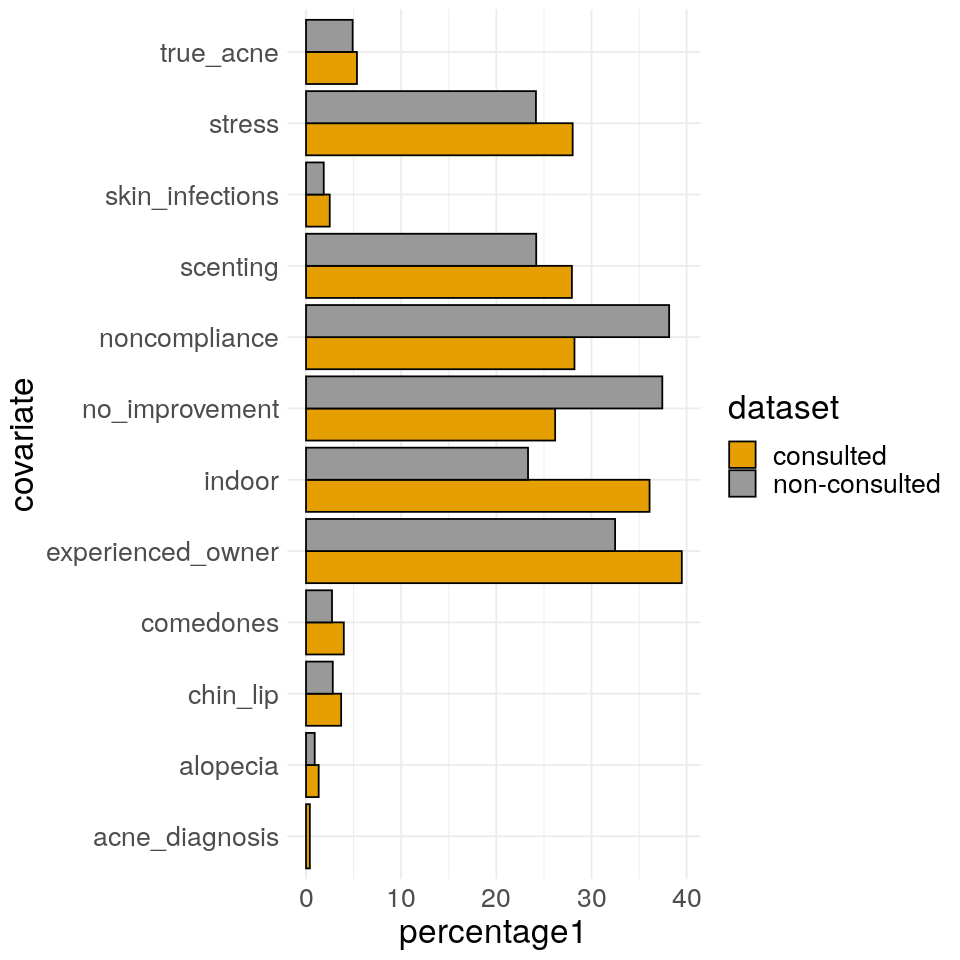

In [47]:
ggplot(data=prevalence_dagitty, aes(x=covariate, y=percentage1, fill=dataset)) +
geom_bar(stat="identity", color="black", position=position_dodge()) +
  theme_minimal() + scale_fill_manual(values=c('#E69F00','#999999')) +
  theme(text = element_text(size = 20)) +
  coord_flip()

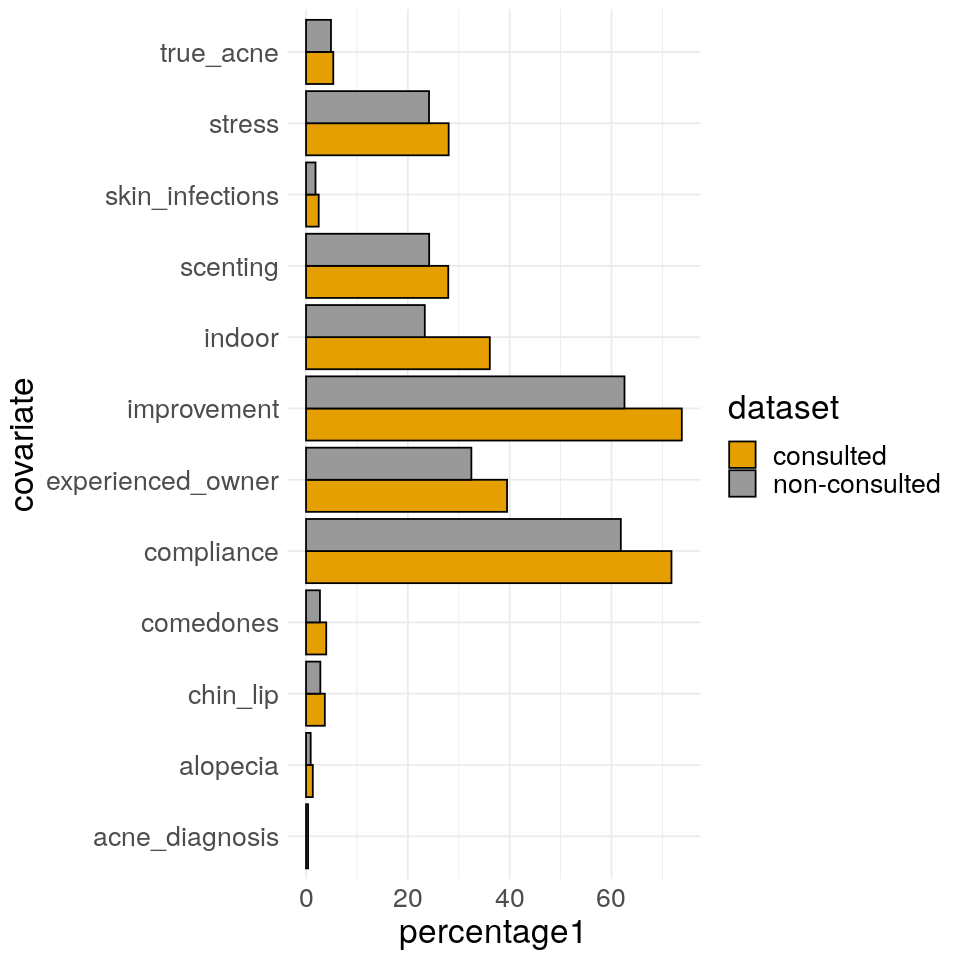

In [48]:
# change to compliance and improvement
prevalence_dagitty[prevalence_dagitty$covariate %in% c('noncompliance','no_improvement'),'percentage1'] <-
    100-prevalence_dagitty[prevalence_dagitty$covariate %in% c('noncompliance','no_improvement'),'percentage1']
prevalence_dagitty[prevalence_dagitty$covariate=='noncompliance','covariate'] <- 'compliance'
prevalence_dagitty[prevalence_dagitty$covariate=='no_improvement','covariate'] <- 'improvement'

ggplot(data=prevalence_dagitty, aes(x=covariate, y=percentage1, fill=dataset)) +
geom_bar(stat="identity", color="black", position=position_dodge()) +
  theme_minimal() + scale_fill_manual(values=c('#E69F00','#999999')) +
  theme(text = element_text(size = 20)) +
  coord_flip()